# Attention và Transformer

Trong câu “Con mèo không nhảy lên bàn vì nó quá cao”, từ “nó” chỉ cái bàn; đổi “cao” thành “mệt” thì “nó” chỉ con mèo. Nghĩa của một từ phụ thuộc vào các từ khác trong câu, và từ nào quan trọng thì thay đổi theo từng câu. Mean pooling ở bài trước lấy trung bình đều mọi từ; attention cho mỗi từ tự chọn lấy thông tin từ những từ nào, với tỉ lệ bao nhiêu. Bài này tính attention bằng tay trên ví dụ nhỏ, rồi cài một khối encoder của Transformer.

> **Mục tiêu**
>
> - Tính attention bằng tay và bằng NumPy.
> - Ghi shape của Q, K, V và đầu ra.
> - Ghép multi-head attention, residual, LayerNorm và feed-forward thành một khối encoder.
> - Dùng padding mask, causal mask và thông tin vị trí.

## Từ trung bình cố định tới trung bình theo câu hỏi

Attention nhận query (câu hỏi), key (thông tin dùng để so khớp) và value (thông tin muốn lấy). Điểm giống nhau giữa query và key quyết định trọng số của value tương ứng. Hình dung truy vấn trong CP: key dùng để tìm, value là dữ liệu cần trả. Khác hash map, attention thường trả tổ hợp mềm của nhiều value thay vì chọn một địa chỉ chính xác.

Đặt $Q$ shape `(Lq, dk)`, $K$ `(Lk, dk)`, $V$ `(Lk, dv)`. Tính

$$S=QK^\top/\sqrt{d_k},\qquad A=\operatorname{softmax}(S),\qquad O=AV.$$

Softmax theo chiều key: mỗi hàng $A$ có tổng 1, nói một query phân phối trọng lượng cho các key ra sao. Query và key cần cùng $d_k$ để nhân vô hướng; value có thể có độ rộng $d_v$ khác. Hệ số $1/\sqrt{d_k}$ giữ thang score khi độ rộng tăng; mục riêng ngay sau ví dụ tính tay giải thích con số này.

**Hỏi nhanh.** Trong một câu, mọi key giống hệt nhau, còn các value thì khác nhau. Output của một query bất kỳ là gì?

- A. Value đầu tiên, vì softmax phá hòa theo chỉ số
- B. Trung bình đều của các value
- C. Vector 0, vì các score triệt tiêu nhau
- D. Không xác định, vì softmax cần các score khác nhau

<details><summary>Đáp án</summary>

B. Trung bình đều của các value

Key giống nhau thì mọi score của query đều bằng nhau. Softmax của $L_k$ số bằng nhau cho mỗi key trọng số $1/L_k$, nên output là trung bình đều của các value, đúng là mean pooling ở bài 3.8. Chọn cứng một phần tử là argmax, không phải softmax. Softmax vẫn xác định khi các score bằng nhau, và score bằng nhau không làm trọng số bằng 0. Attention mở rộng mean pooling bằng cách để query và key quyết định trọng số.

</details>

## Ví dụ tính tay

Lấy một query $q=[1]$, hai key $k_1=[1]$, $k_2=[0]$, nên $d_k=1$ và score là $[1,0]$. Softmax cho $a_1=e/(e+1)\approx0.731$, $a_2=1/(e+1)\approx0.269$. Với $v_1=[2,0]$, $v_2=[0,4]$, kết quả là $[2a_1,4a_2]\approx[1.462,1.076]$. Key quyết định hệ số, value cung cấp nội dung.

Khi trọng số đã có, đầu ra chỉ là trung bình có trọng số: $(0.5, 0.3, 0.2)$ trên các value 2, 4, 10 cho $1 + 1.2 + 2 = 4.2$. Nếu mọi key giống hệt nhau thì mọi score bằng nhau, và đầu ra là trung bình cộng các value, query là gì cũng vậy.



In [ ]:
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(41)
Q = np.array([[1.]])
K = np.array([[1.], [0.]])
V = np.array([[2., 0.], [0., 4.]])
scores = Q @ K.T / np.sqrt(Q.shape[-1])
shifted = scores - scores.max(axis=-1, keepdims=True)
weights = np.exp(shifted)
weights /= weights.sum(axis=-1, keepdims=True)
output = weights @ V
print('weights:', np.round(weights, 6).tolist())
print('output:', np.round(output, 6).tolist())
tq, tk, tv = [torch.tensor(a) for a in [Q, K, V]]
torch_output = (tq @ tk.T / np.sqrt(Q.shape[-1])).softmax(dim=-1) @ tv
print('match:', np.allclose(output, torch_output.numpy()))

weights: [[0.731059, 0.268941]]
output: [[1.462117, 1.075766]]
match: True


Trừ max trước exp không đổi softmax vì mọi số mũ cùng chia một hệ số; nó tránh exp của số quá lớn. Đây là cùng tư duy phép số ổn định như loss bài 3.3. Dòng `match` xác nhận phép tự cài trùng với phép tensor của PyTorch.

**Hỏi nhanh.** `scores` có shape `(B, Lq, Lk)`. Trong `weights = scores.softmax(dim=...)`, phải chọn `dim` nào để mỗi query phân trọng số cho các key?

- A. `dim=0`
- B. `dim=1`
- C. `dim=-1`
- D. Chiều nào cũng được, vì shape giữ nguyên

<details><summary>Đáp án</summary>

C. `dim=-1`

Chiều cuối là $L_k$: mỗi hàng ứng với một query, và cộng lại bằng 1. `dim=1` là chuẩn hóa theo query, tức mỗi key chia trọng số cho các query. Code vẫn chạy, shape vẫn đúng, nhưng phép tính đã khác. `dim=0` trộn các câu khác nhau trong batch. Shape không bắt được lỗi này, nên kiểm thêm xem `weights.sum(dim=-1)` có bằng 1 không.

</details>

## Score quá lớn làm softmax bão hòa

Score $q^\top k=\sum_{i=1}^{d_k}q_ik_i$ là tổng của $d_k$ tích. Nếu các thành phần của $q$ và $k$ độc lập, trung bình 0, phương sai 1, mỗi tích có phương sai 1, nên score có phương sai $d_k$ và độ lệch chuẩn $\sqrt{d_k}$. Score càng chênh nhau, softmax càng dồn trọng số vào một key. Khi phân phối gần one-hot, softmax bão hòa: gradient tới các key còn lại gần bằng 0, giống tanh bão hòa ở bài 3.3. Chia cho $\sqrt{d_k}$ đưa độ lệch chuẩn về khoảng 1 ở mọi độ rộng.

Thí nghiệm dưới lấy 2000 query ngẫu nhiên, mỗi query 8 key, đo độ lệch chuẩn của score và trung bình trọng số lớn nhất trong mỗi hàng:

In [ ]:
rng = np.random.default_rng(0)

def mean_top_weight(scores):
    shifted = scores - scores.max(axis=-1, keepdims=True)
    weights = np.exp(shifted)
    weights /= weights.sum(axis=-1, keepdims=True)
    return weights.max(axis=-1).mean()

for d_k in [4, 64, 1024]:
    q = rng.standard_normal((2000, 1, d_k))   # 2000 query
    k = rng.standard_normal((2000, 8, d_k))   # 8 key cho mỗi query
    raw = (q * k).sum(axis=-1)                # score chưa chia, shape (2000, 8)
    scaled = raw / np.sqrt(d_k)
    print(f'd_k={d_k:<4}  std {raw.std():5.2f} -> {scaled.std():4.2f}   '
          f'max weight {mean_top_weight(raw):.3f} -> {mean_top_weight(scaled):.3f}')

d_k=4     std  2.00 -> 1.00   max weight 0.524 -> 0.342
d_k=64    std  7.96 -> 0.99   max weight 0.878 -> 0.360
d_k=1024  std 31.83 -> 0.99   max weight 0.968 -> 0.358


Không chia, độ lệch chuẩn tăng đúng như $\sqrt{d_k}$ (2, 8, 32) và key mạnh nhất chiếm trung bình 0.524, 0.878 rồi 0.968 trọng số, trong khi chia đều cho 8 key chỉ là 0.125. Có chia, độ lệch chuẩn ở quanh 1 và trọng số lớn nhất giữ quanh 0.35 ở cả ba độ rộng: thang score không còn phụ thuộc kích thước model.

Lập luận dựa trên giả định độc lập lúc khởi tạo; trong quá trình học, model vẫn có thể làm score lớn khi thật sự cần một phân phối nhọn. Đẩy tới cùng, nhân mọi score với $c \to \infty$ thì softmax thành one-hot và đầu ra chỉ còn value của key có score lớn nhất.



**Hỏi nhanh.** Các thành phần của $q$ và $k$ độc lập, trung bình 0, phương sai 1, với $d_k = 256$. Độ lệch chuẩn của score trước và sau khi chia cho $\sqrt{d_k}$ là bao nhiêu?

- A. 256 trước, 16 sau
- B. 256 trước, 1 sau
- C. 1 trước, 1/16 sau
- D. 16 trước, 1 sau

<details><summary>Đáp án</summary>

D. 16 trước, 1 sau

Score là tổng của 256 tích có phương sai 1, nên có phương sai 256, tức độ lệch chuẩn 16. Chia cho $\sqrt{256} = 16$ thì còn 1. “256 trước” là nhầm phương sai với độ lệch chuẩn. “1 trước” là tưởng các thành phần chuẩn thì tổng cũng chuẩn, quên rằng phương sai cộng dồn qua $d_k$ số hạng.

</details>

## Self-attention học cách tạo câu hỏi

Trong self-attention, $Q$, $K$, $V$ đều được tạo từ cùng chuỗi $X$ nhưng qua ba phép chiếu học được: $Q=XW_Q$, $K=XW_K$, $V=XW_V$. Cùng token có ba vai trò khác nhau. Query của một vị trí hỏi nên lấy thông tin gì; key của các vị trí giúp so khớp; value mang dữ liệu được trộn. Ba ma trận được học từ loss, nên từng phần tử của chúng không mang một quy tắc ngữ nghĩa đặt sẵn.

| Đại lượng một head | Shape có batch | Ý nghĩa |
|---|---|---|
| $X$ | `(B,L,d)` | Vector token đầu vào |
| $Q$, $K$ | `(B,L,dk)` | Dùng so khớp |
| $V$ | `(B,L,dv)` | Nội dung cần trộn |
| score, weights | `(B,L,L)` | Mỗi query nhìn mọi key |
| $O$ | `(B,L,dv)` | Biểu diễn đã nhận ngữ cảnh |

Multi-head attention dùng nhiều bộ chiếu, tạo nhiều cách trộn song song, ghép các kết quả rồi chiếu lại. Mỗi head có softmax riêng, nên một query có $H$ phân phối trọng số cùng lúc: một head có thể dồn vào chủ ngữ, head khác vào từ đứng kề. Nhiều head không bảo đảm mỗi head ứng với một khái niệm con người đặt tên được; chúng chỉ là thêm cách tương tác để model học.

Với `embed_dim` $d$ và số head $H$ của lớp PyTorch trong bài, cần $d$ chia hết cho $H$, mỗi head rộng $d/H$. Ba phép chiếu $W_Q,W_K,W_V$ và phép chiếu ra $W_O$ đều là $d\times d$, nên lớp có $4d^2+4d$ tham số kể cả bias, không phụ thuộc $H$: với $d=512$ là $4\cdot512^2+4\cdot512=1\,050\,624$ cho cả 8 lẫn 16 head.

**Hỏi nhanh.** Bỏ hai phép chiếu $W_Q$, $W_K$, dùng thẳng $Q = K = X$. Ma trận score $XX^\top$ bị ràng buộc gì?

- A. Đối xứng: score từ $i$ tới $j$ bằng score từ $j$ tới $i$
- B. Mọi score bằng nhau, nên attention thành mean
- C. Các score ngoài đường chéo luôn bằng 0
- D. Không bị ràng buộc gì, vì $W_V$ vẫn được học

<details><summary>Đáp án</summary>

A. Đối xứng: score từ $i$ tới $j$ bằng score từ $j$ tới $i$

$(XX^\top)^\top = XX^\top$, nên điểm token $i$ dành cho $j$ bằng điểm $j$ dành cho $i$, trước softmax. Quan hệ một chiều, như “động từ đi tìm chủ ngữ”, cần score không đối xứng, nên cần $W_Q \neq W_K$. Mọi score bằng nhau chỉ xảy ra trong trường hợp đặc biệt, như khi mọi token giống nhau. Score ngoài đường chéo bằng 0 chỉ khi các vector vuông góc với nhau. $W_V$ chỉ đổi nội dung được trộn, không đổi trọng số.

</details>

## Mask bỏ vị trí nào?

Có hai loại mask, giải quyết hai lý do khác nhau và có thể dùng cùng lúc:

- **Padding mask** bỏ các key PAD.
- **Causal mask** bỏ key tương lai để vị trí $t$ không nhìn $t+1$ trở đi, cần khi mô hình dự đoán token tiếp theo. Encoder đọc toàn câu thường không dùng causal mask; decoder sinh từng token (tự hồi quy) cần nó.

BERT là encoder, mỗi token nhìn cả hai phía; GPT là decoder, mỗi token chỉ nhìn bên trái. Causal mask viết bằng `torch.tril(torch.ones(T, T)).bool()` hay `~torch.triu(torch.ones(T, T), diagonal=1).bool()` đều như nhau: vị trí $i$ nhìn $j$ khi $j \le i$.



Ta đưa score của vị trí cấm về $-\infty$ **trước softmax**, nên trọng số đó bằng 0. Nếu một hàng bị cấm mọi key, softmax không còn phân phối hợp lệ; tránh câu rỗng hoặc chọn quy tắc rõ cho trường hợp ấy. Nếu mask sau softmax mà không chuẩn hóa lại, tổng weights không còn 1 và không còn cùng phép attention.

Ví dụ score $[1, 2, 3]$ với key thứ ba là PAD: softmax chỉ còn trên $[1, 2]$, cho $(0.269, 0.731, 0)$. Với mask đúng, thêm bao nhiêu PAD thì biểu diễn của token thật cũng không đổi.

Quy ước True/False của mask khác nhau giữa các hàm:

- Trong `nn.MultiheadAttention`, `key_padding_mask=True` nghĩa là bỏ key; `attn_mask=True` nghĩa là cấm cặp query-key. Causal mask vì vậy thường viết `torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)`, True ở các ô trên đường chéo, tức key tương lai. Code bài 3.8 có `valid_mask` True ở token thật, nên truyền `key_padding_mask=~valid_mask`.
- `F.scaled_dot_product_attention` dùng quy ước ngược lại: True nghĩa là **được** tham gia attention.

Đọc tài liệu của đúng hàm đang gọi; không chuyển mask nguyên xi chỉ vì tên tham số giống nhau.



**Hỏi nhanh.** Causal mask cho MHA được viết `torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=0)` thay vì `diagonal=1`. Chuyện gì xảy ra?

- A. Không đổi gì, vì đường chéo không ảnh hưởng softmax
- B. Mỗi query nhìn thêm được một token tương lai
- C. Query 0 bị cấm mọi key, nên output có thể ra NaN
- D. Chỉ chậm hơn một chút, vì phải cấm thêm $L$ ô

<details><summary>Đáp án</summary>

C. Query 0 bị cấm mọi key, nên output có thể ra NaN

`diagonal=0` đặt True cả đường chéo, nên mỗi query bị cấm đọc chính nó. Hàng 0 không còn key nào, mà softmax của một hàng toàn $-\infty$ không xác định và thường ra NaN. Các query khác thì mất thông tin của chính token ấy. Mask cấm nhiều hơn chứ không ít hơn, nên không có chuyện nhìn thêm tương lai, và chi phí gần như không đổi. In một mask $3\times 3$ ra trước khi train là bắt được lỗi này.

</details>

**Hỏi nhanh.** Một hàng weights là `[0.5, 0.3, 0.2]`, trong đó key thứ ba là PAD. Code đặt weight của PAD về 0 **sau** softmax. Để khớp với cách đặt score bằng $-\infty$ trước softmax, weight của key đầu phải bằng bao nhiêu?

- A. 0.5
- B. 0.7
- C. 0.8
- D. 0.625

<details><summary>Đáp án</summary>

D. 0.625

Đặt score $-\infty$ trước softmax cũng như bỏ key ấy đi rồi chuẩn hóa trên phần còn lại, nên tỉ lệ giữa các key thật giữ nguyên: $0.5/(0.5 + 0.3) = 0.625$. Giữ 0.5 thì tổng của hàng chỉ còn 0.8, và output bị co về phía 0. 0.8 là tổng còn lại, không phải trọng số. Dồn 0.2 sang key đầu, ra 0.7, thì lệch tỉ lệ giữa hai key thật.

</details>

## Một encoder block nhỏ

Một encoder block ghép bốn thành phần:

- **Attention** trộn thông tin giữa các token, cho output cùng shape với input.
- **Residual** (kết nối tắt) cộng input vào output, giữ một đường thông tin và gradient đi thẳng.
- **LayerNorm** (bài 3.6) chuẩn hóa theo feature trong từng token.
- **Feed-forward network (FFN)** là một MLP nhỏ áp riêng cho từng vị trí, biến đổi feature sau khi đã trộn ngữ cảnh.

Ta cài kiểu post-norm: `norm(x + attention(x))`, rồi `norm(x + FFN(x))`. Nhiều model dùng pre-norm, `x + attention(norm(x))`: đường residual đi thẳng không qua norm nào, nên mạng rất sâu học ổn định hơn và ít phụ thuộc warmup. Vị trí norm là một lựa chọn kiến trúc, phải giữ đúng khi nạp checkpoint.



In [ ]:
class TinyEncoder(nn.Module):
    def __init__(self, width=4, heads=2):
        super().__init__()
        self.attention = nn.MultiheadAttention(width, heads, batch_first=True, dropout=0.)
        self.norm1 = nn.LayerNorm(width)
        self.ffn = nn.Sequential(nn.Linear(width, 8), nn.ReLU(), nn.Linear(8, width))
        self.norm2 = nn.LayerNorm(width)

    def forward(self, x, padding_mask=None, causal_mask=None):
        attended, weights = self.attention(x, x, x,
            key_padding_mask=padding_mask, attn_mask=causal_mask,
            need_weights=True, average_attn_weights=False)
        x = self.norm1(x + attended)
        x = self.norm2(x + self.ffn(x))
        return x, weights

block = TinyEncoder()
block.eval()
x = torch.randn(2, 3, 4)
padding_mask = torch.tensor([[False, False, True], [False, False, False]])
with torch.no_grad():
    encoded, attn = block(x, padding_mask=padding_mask)
print('output:', tuple(encoded.shape))
print('weights:', tuple(attn.shape))
print('PAD key max weight:', round(attn[0, :, :, 2].abs().max().item(), 6))
print('weight row sums:', torch.allclose(attn.sum(dim=-1), torch.ones(2, 2, 3), atol=1e-6))

output: (2, 3, 4)
weights: (2, 2, 3, 3)
PAD key max weight: 0.0
weight row sums: True


Đầu ra `(2,3,4)` giữ batch, độ dài và độ rộng; weights `(2,2,3,3)` gồm batch, head, query, key vì không lấy mean qua head. Cột PAD của mẫu đầu bằng 0 cho cả hai head. Hàng query tại PAD vẫn có thể sinh vector: key padding mask chỉ bỏ key. Khi gộp thành vector câu hoặc tính token loss, còn phải dùng valid mask để bỏ query PAD ở bước đó.



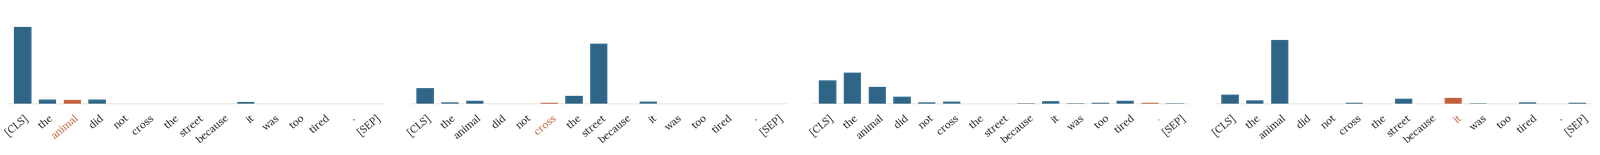

**Hỏi nhanh.** Gọi `self.attention(x, x, x, key_padding_mask=padding_mask)` với mặc định `average_attn_weights=True`, cùng `x` có shape `(2, 3, 4)` và 2 head. `weights` có shape gì?

- A. `(2, 2, 3, 3)`
- B. `(2, 3, 3)`
- C. `(2, 3, 4)`
- D. `(3, 3)`

<details><summary>Đáp án</summary>

B. `(2, 3, 3)`

Mặc định là lấy trung bình qua các head, nên mất chiều head, chỉ còn batch, query và key. `(2, 2, 3, 3)` là khi đặt `average_attn_weights=False` như trong bài. `(2, 3, 4)` là shape của output, không phải của weights. `(3, 3)` là quên chiều batch. Muốn xem từng head thì đặt `False`.

</details>

## Thử causal mask bằng perturbation

Một phép kiểm có ý nghĩa hơn chỉ nhìn ma trận mask là thay token tương lai và xem quá khứ có đổi không. Với ba vị trí, cấm phần tam giác trên. Ta sửa token cuối rồi so đầu ra hai token đầu, giữ eval và `dropout=0`:

In [ ]:
causal = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)
one_sequence = x[1:2].clone()
changed = one_sequence.clone()
changed[:, 2, :] += torch.tensor([10., -3., 7., 2.])
with torch.no_grad():
    before, _ = block(one_sequence, causal_mask=causal)
    after, _ = block(changed, causal_mask=causal)
print('past unchanged:', torch.allclose(before[:, :2], after[:, :2], atol=1e-6))
print('last position changed:', not torch.allclose(before[:, 2], after[:, 2], atol=1e-6))

past unchanged: True
last position changed: True


Dòng đầu xác nhận hai vị trí đầu không dùng token cuối. Dòng thứ hai là đối chứng: vị trí cuối phải đổi, nếu không thì dòng đầu có thể True chỉ vì block bỏ qua phần input bị sửa. Cách kiểm này có cùng tinh thần tạo input đối kháng nhỏ trong CP: thay phần bị cấm rồi xem output có chịu ảnh hưởng. Với model nhiều layer, chạy cùng test trên toàn model, vì chỉ một khâu trộn cả chuỗi (pooling, chuẩn hóa theo chiều độ dài) cũng đủ làm tương lai lọt vào.

**Hỏi nhanh.** Vẫn block có causal mask ấy, nhưng lần này sửa token ở **vị trí 0** thay vì token cuối. Output ở những vị trí nào được phép thay đổi?

- A. Chỉ vị trí 0
- B. Vị trí 1 và 2, còn vị trí 0 giữ nguyên
- C. Không vị trí nào, vì causal mask đã chặn
- D. Cả ba vị trí 0, 1 và 2

<details><summary>Đáp án</summary>

D. Cả ba vị trí 0, 1 và 2

Causal mask chỉ cấm đọc tương lai. Mọi query từ vị trí 0 trở đi đều được đọc key 0, nên cả ba đầu ra đều có thể đổi. “Chỉ vị trí 0” là nhầm causal mask với mask chỉ cho đọc chính mình. “1 và 2” là quên rằng vị trí 0 đọc chính nó, lại còn nhánh residual. “Không vị trí nào” là nhầm hướng, vì causal mask chặn tương lai chứ không chặn quá khứ.

</details>

## Thứ tự cần thông tin vị trí

Phép kiểm sau dùng block không có thông tin vị trí và không mask, ở chế độ eval với `dropout=0`. Khi ấy self-attention và FFN có tính **equivariant** theo hoán vị: đảo thứ tự token đầu vào thì các vector đầu ra đảo theo đúng cách đó. Một mean pooling đặt sau block còn **bất biến** (invariant): đảo token không đổi vector câu. Block vẫn tạo vector riêng ở mỗi vị trí, nhưng không tự biết token nào đứng thứ hai.

Nếu có mask, phải hoán vị mask cùng hàng query và cột key; một causal mask giữ cố định đã mang thông tin thứ tự nên phá tính chất này.

In [ ]:
permutation = torch.tensor([2, 0, 1])
with torch.no_grad():
    original, _ = block(one_sequence)
    permuted, _ = block(one_sequence[:, permutation])
print('equivariant without positions:', torch.allclose(
    permuted, original[:, permutation], atol=1e-6))

equivariant without positions: True


True ở đây là tính chất toán học, không phải lỗi thư viện. Positional encoding cộng vào mỗi token một vector cho biết nơi nó xuất hiện. Ba cách thường gặp là bảng vị trí học được, sin/cos cố định và relative position. Bản sin/cos dùng $PE_{p,2i}=\sin(p/10\,000^{2i/d})$, $PE_{p,2i+1}=\cos(p/10\,000^{2i/d})$; với $d=4$, hai tần số là 1 và 0.01. Đoạn sau kiểm nó:

In [ ]:
positions = torch.arange(3, dtype=torch.float32).unsqueeze(1)
frequencies = torch.exp(-np.log(10000.) * torch.arange(0, 4, 2) / 4)
pe = torch.zeros(3, 4)
pe[:, 0::2] = torch.sin(positions * frequencies)
pe[:, 1::2] = torch.cos(positions * frequencies)
with torch.no_grad():
    ordered, _ = block(one_sequence + pe)
    swapped, _ = block(one_sequence[:, permutation] + pe)
print('position 0:', pe[0].tolist())
print('equivariant with fixed slots:', torch.allclose(swapped, ordered[:, permutation], atol=1e-6))

position 0: [0.0, 1.0, 0.0, 1.0]
equivariant with fixed slots: False


Khi đảo token nhưng giữ bảng vị trí tại các slot 0, 1, 2, ta đổi quan hệ token–vị trí, nên dòng cuối thành False: block giờ phân biệt được thứ tự. Sin/cos chỉ cung cấp tín hiệu; model dùng tín hiệu ấy đến đâu là do huấn luyện.



Relative position không gắn vị trí tuyệt đối vào token mà đưa khoảng cách có hướng $j-i$ vào score, chẳng hạn $q_i^\top(k_j+r_{j-i})/\sqrt{d_k}$ với $r_{j-i}$ là vector học được. Mọi cặp cách nhau cùng một khoảng dùng chung một vector, hợp với dữ liệu mà quan hệ phụ thuộc khoảng cách hơn vị trí tuyệt đối, như chuỗi thời gian. Bảng vị trí học được thì là một `nn.Embedding(max_len, d)`, nên chuỗi dài hơn `max_len` cần quy tắc rõ từ trước: bảng 512 vị trí không có hàng cho token thứ 600.

Với $T$ token, khoảng cách $j - i$ nhận $2T - 1$ giá trị, từ $-(T-1)$ tới $T-1$. Sin/cos tính được ở mọi vị trí, và dịch một khoảng cố định là một phép quay trên từng cặp chiều, nên model dễ đọc ra khoảng cách tương đối. Cùng công thức sin/cos còn dùng để đưa một con số như bước khử nhiễu $t$ vào mạng (bài 5.8).

**Hỏi nhanh.** Bảng vị trí học được là `nn.Embedding(512, d)`. Tập test có một câu dài 600 token. Nếu không xử lý gì, chuyện gì xảy ra?

- A. Các vị trí từ 512 tới 599 tự nội suy từ những vị trí đã học
- B. Các vị trí từ 512 trở đi dùng chung vector của vị trí 511
- C. Tra vị trí từ 512 trở đi sẽ báo lỗi chỉ số
- D. Chạy bình thường, vì attention không giới hạn độ dài

<details><summary>Đáp án</summary>

C. Tra vị trí từ 512 trở đi sẽ báo lỗi chỉ số

Bảng chỉ có 512 hàng, chỉ số từ 0 tới 511. Tra chỉ số 512 sẽ báo `IndexError`, giống ID ngoài vocabulary ở bài 3.8. Không có chuyện tự nội suy hay tự kẹp. Phải chọn trước cách xử lý: cắt bớt, chia cửa sổ, hoặc dùng cách mã hóa vị trí không bị giới hạn bởi bảng. Bản thân attention không giới hạn độ dài, nhưng bảng vị trí thì có. Hãy chạy thử câu dài nhất của test trước khi nộp.

</details>

## Kiểm graph và đọc attention đúng mức

Để bảo đảm encoder nhỏ có đường gradient, ta nối một loss kiểm với mục tiêu ngẫu nhiên có shape đúng. Không dùng chỉ bình phương đầu ra LayerNorm rồi kết luận gradient lớn hay nhỏ, vì norm đã cố định một số thống kê đầu ra.

In [ ]:
block.train()
block.zero_grad(set_to_none=True)
encoded, _ = block(x, padding_mask=padding_mask)
target = torch.randn_like(encoded)
valid = ~padding_mask
loss = ((encoded - target).square().mean(dim=-1) * valid).sum() / valid.sum()
loss.backward()
print('finite loss:', torch.isfinite(loss).item())
print('all parameter gradients finite:', all(p.grad is not None and torch.isfinite(p.grad).all()
                                             for p in block.parameters()))

finite loss: True
all parameter gradients finite: True


Hai True xác nhận loss hữu hạn và mọi tham số đều nhận gradient hữu hạn, kể cả khi có mask PAD: block sẵn sàng để huấn luyện.

Attention weights là hệ số trộn tại một layer/head; chúng không tự là lời giải thích nhân quả cho dự đoán cuối, vì model còn residual, FFN, nhiều head và layer khác. Muốn biết token ảnh hưởng kết quả thế nào, cần perturbation hoặc ablation: xóa hay thay token rồi đo dự đoán đổi bao nhiêu.

**Hỏi nhanh.** Trong model phân loại cảm xúc, một head ở lớp cuối dồn 0.9 trọng số vào từ “không”. Kết luận nào có cơ sở?

- A. Mới chỉ biết hệ số trộn, phải thử bỏ hoặc thay từ ấy mới kết luận được
- B. Từ “không” là nguyên nhân chính của dự đoán
- C. Head này chuyên xử lý phủ định, có thể bỏ các head khác
- D. Head này bị lỗi, vì trọng số tốt phải trải đều

<details><summary>Đáp án</summary>

A. Mới chỉ biết hệ số trộn, phải thử bỏ hoặc thay từ ấy mới kết luận được

Trọng số 0.9 chỉ nói head ấy trộn chủ yếu vector tại “không”. Residual, FFN và các head khác vẫn đưa thông tin của mọi token tới đầu ra. Thay hoặc xóa “không” rồi đo logit đổi bao nhiêu thì mới biết được ảnh hưởng. Gọi nó là “head phủ định” thì phải kiểm trên nhiều câu, và bỏ các head khác cũng phải đo. Phân phối nhọn không phải lỗi, vì scaled dot-product cho phép điều đó khi các score chênh nhau nhiều.

</details>

## Chi phí của attention

Attention mọi cặp tốn khoảng $O(BL^2d)$ tính toán ở phần score và trộn, cùng $O(BHL^2)$ bộ nhớ cho score nếu lưu đủ ma trận; các phép chiếu thêm $O(BLd^2)$. Tăng $L$ gấp đôi thì phần score gấp bốn. Padding cũng trả theo $L^2$: một câu rất dài kéo cả batch lên độ dài của nó, nên xếp các câu dài gần nhau vào cùng batch (bucketing), cắt hoặc chia cửa sổ văn bản dài trước khi nghĩ tới phần cứng lớn hơn.



Bậc hai đến từ việc softmax buộc tạo đủ ma trận $L\times L$: $\exp(q_i^\top k_j)$ không viết được thành tích vô hướng $\phi(q_i)^\top\phi(k_j)$ với $\phi$ hữu hạn chiều.

Linear attention thay hẳn nó bằng $\phi(q_i)^\top\phi(k_j)$ với một feature map $\phi$ hữu hạn chiều; khi đó có thể đổi thứ tự nhân ma trận như bài toán nhân chuỗi ma trận quen thuộc trong CP, và chi phí còn tuyến tính theo $L$, cỡ $O(Ld^2)$. Với mask nhân quả, chỉ cần giữ hai tổng chạy $S_t = \sum_{j \le t}\phi(k_j)v_j^\top$ và $z_t = \sum_{j \le t}\phi(k_j)$, nên sinh mỗi token tốn bộ nhớ không đổi. $\phi$ phải dương, như $1 + \operatorname{ELU}(x)$, để trọng số không âm và mẫu số không bằng 0.

Với dữ liệu ít, model phức tạp chưa chắc thắng baseline masked mean; so trên cùng validation trước khi chuyển sang model pretrained ở chương 4.

**Hỏi nhanh.** Một batch 32 câu: 31 câu dài khoảng 100 token, một câu dài 2000 token. Cả batch được pad lên 2000. Cách rẻ nhất để giảm lãng phí là gì?

- A. Xếp những câu có độ dài gần nhau vào cùng batch
- B. Tăng số head để chia nhỏ ma trận score
- C. Bỏ `key_padding_mask` để khỏi phải tính phần PAD
- D. Giảm `embed_dim` để ma trận score nhỏ lại

<details><summary>Đáp án</summary>

A. Xếp những câu có độ dài gần nhau vào cùng batch

Ma trận score của mỗi câu là $2000^2$ thay vì $100^2$, tức gấp 400 lần, và gần như toàn là PAD. Gom các câu dài vào batch riêng thì 31 câu còn lại chỉ phải pad tới khoảng 100. Score có shape $(B, H, L, L)$, nên thêm head chỉ làm nặng hơn, còn giảm $d$ không đổi kích thước score. Bỏ mask không bớt được phép tính nào, mà còn để token thật đọc cả PAD.

</details>

## Khi đi thi

- **Kiểm quy ước mask trước khi train.** In một mask 3×3 và đọc tài liệu của đúng hàm đang gọi: `nn.MultiheadAttention` dùng True là cấm, `F.scaled_dot_product_attention` dùng True là được đọc. Chạy test thay token tương lai và test thêm PAD trên model thật.
- **Tính bộ nhớ score trước khi chọn `max_length`.** Mỗi layer cần cỡ $B\cdot H\cdot L^2$ số khi lưu đủ ma trận score; tăng $L$ gấp đôi là gấp bốn. Ước lượng trên giấy rẻ hơn một lần OOM giữa giờ thi.
- **Giảm padding.** Bucketing theo độ dài, cắt hoặc chia cửa sổ văn bản dài; xem thông tin nằm ở đầu hay cuối văn bản trước khi chọn cách cắt.
- **Kiểm cả shape lẫn giá trị.** Sai `batch_first`, softmax sai `dim` hay quên chia $\sqrt{d_k}$ đều giữ shape đúng nên assert shape không bắt được; kiểm thêm `weights.sum(-1)` bằng 1 và xem weights có quá nhọn ngay lúc khởi tạo không.
- **So baseline trước.** Với dữ liệu ít, một masked mean trên cùng validation là mốc cần thắng; Transformer tự train từ đầu cần nhiều dữ liệu, còn model pretrained là chủ đề chương sau.
- **Không đọc attention weights như lời giải thích.** Khi cần biết token nào quan trọng, dùng ablation hoặc perturbation.

## Tóm tắt

- Attention là trung bình có trọng số của value, trọng số lấy từ softmax của score query-key; chia $\sqrt{d_k}$ giữ softmax khỏi bão hòa.
- Self-attention học ba phép chiếu Q, K, V; multi-head tạo nhiều cách trộn với cùng số tham số.
- Encoder block: attention, residual, LayerNorm, FFN.
- Padding mask bỏ PAD, causal mask bỏ tương lai; thông tin vị trí cho model biết thứ tự.
- Chi phí bậc hai theo độ dài quyết định ngữ cảnh dài được bao nhiêu.

## Kiểm tra cuối bài

**Câu 1.** Một đội tự cài multi-head self-attention:

```py
Q = self.q_proj(x).view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
K = self.k_proj(x).view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
scores = Q @ K.transpose(-2, -1)          # dòng A
attn = F.softmax(scores, dim=-1)
```

Khi chạy, trọng số attention rất nhọn: một vị trí nhận khoảng 99% trọng số. Dòng A thiếu phép nào?

- A. Chia cho `self.head_dim`, tức số chiều được cộng
- B. Chia cho `math.sqrt(self.head_dim)`
- C. Chia cho `math.sqrt(self.num_heads)` để cân các head
- D. Thay bằng cosine của Q và K đã chuẩn hóa

<details><summary>Đáp án</summary>

B. Chia cho `math.sqrt(self.head_dim)`

Mỗi score là tổng của `head_dim` tích, nên có độ lệch chuẩn cỡ $\sqrt{d_k}$. Chia cho $\sqrt{d_k}$ đưa nó về khoảng 1, và softmax hết bão hòa. Chia cho `head_dim` là quá tay: độ lệch chuẩn chỉ còn $1/\sqrt{d_k}$, và lúc đầu attention gần như đều. Số head không nằm trong tích vô hướng của một head, nên không phải thang cần sửa. Cosine bị chặn trong $[-1, 1]$, đổi hẳn cơ chế và cần thêm một nhiệt độ, nên không phải phép còn thiếu của scaled dot-product.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 17](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=26)

</details>

**Câu 2.** Hai cấu hình self-attention cùng `embed_dim=512`: một head rộng 512, hoặc 8 head, mỗi head rộng 64. Lợi ích chính của 8 head là gì?

- A. Ít tham số hơn tám lần, vì mỗi head hẹp hơn
- B. Chi phí theo độ dài giảm từ bậc hai về tuyến tính
- C. Mỗi query có tám phân phối trọng số cùng lúc
- D. Mỗi head chắc chắn học một quan hệ ngữ pháp riêng

<details><summary>Đáp án</summary>

C. Mỗi query có tám phân phối trọng số cùng lúc

Một head chỉ có một softmax cho mỗi query, nên mọi loại thông tin phải trộn bằng cùng một bộ trọng số. Tám head cho tám cách trộn song song, trong tám không gian con, rồi ghép lại và chiếu thêm một lần. Số tham số ở cả hai cấu hình vẫn là $4d^2 + 4d$. Mỗi head vẫn tạo ma trận score $L\times L$, nên chi phí vẫn là bậc hai. Head không được gán nhãn ngữ pháp sẵn; mỗi head làm gì là do quá trình huấn luyện quyết định.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q2.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=12)

</details>

**Câu 3.** Code cũ dùng `nn.MultiheadAttention` với `causal = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)`. Đội chuyển sang `F.scaled_dot_product_attention`, nơi mask boolean True nghĩa là **được** tham gia attention. Phải truyền gì để giữ đúng phép tính?

- A. `attn_mask=causal`, vì cùng là mask boolean
- B. `attn_mask=~causal`, hoặc `is_causal=True`
- C. `attn_mask=causal.T`, vì hàm này đọc theo cột
- D. `attn_mask=causal.float()`, để thành mask cộng

<details><summary>Đáp án</summary>

B. `attn_mask=~causal`, hoặc `is_causal=True`

`causal` có True ở các ô tương lai, nghĩa là cấm theo quy ước của MHA. Hàm mới lại hiểu True là cho phép, nên phải đảo lại, hoặc dùng cờ `is_causal=True` có sẵn. Truyền nguyên `causal` thì mỗi query chỉ đọc được tương lai, còn query cuối không có key nào. `causal.T` cho phép đọc quá khứ nhưng bỏ chính đường chéo, nên query 0 không còn key nào. Mask kiểu float được cộng vào score: cộng 1 vào ô tương lai không cấm gì, lại còn ưu tiên tương lai.

</details>

**Câu 4.** Chuỗi có 4 vị trí, dùng left padding: vị trí 0 là PAD, token thật ở các vị trí 1, 2, 3. Model dùng cả causal mask lẫn key padding mask. Query ở vị trí 2 được đọc những key nào?

- A. 0, 1, 2
- B. 1, 2, 3
- C. Chỉ 2
- D. 1, 2

<details><summary>Đáp án</summary>

D. 1, 2

Causal mask bỏ key 3, vì nó nằm ở tương lai. Padding mask bỏ key 0, vì nó là PAD. Còn lại 1 và 2, gồm cả chính vị trí 2. “0, 1, 2” là quên padding mask. “1, 2, 3” là quên causal mask. “Chỉ 2” là nhầm causal mask với mask chỉ cho đọc chính mình. Hai mask có lý do khác nhau và được kết hợp: một ô bị cấm nếu bất kỳ mask nào cấm nó.

</details>

**Câu 5.** Key padding mask đã bỏ các key PAD, nhưng output tại một query PAD vẫn khác 0. Muốn gộp thành vector của cả câu, ta phải làm gì?

- A. Đổi mask key thành toàn True để mọi output bằng 0
- B. Gọi `zero_grad` để xóa output ở vị trí PAD
- C. Bỏ các query PAD ra khỏi bước gộp, bằng valid mask
- D. Sửa attention, vì mask phải xóa cả hàng query

<details><summary>Đáp án</summary>

C. Bỏ các query PAD ra khỏi bước gộp, bằng valid mask

Key padding mask chỉ quyết định cột nào được đọc. Hàng query tại PAD vẫn đọc các token thật và vẫn sinh ra một vector. Bước gộp và loss phải tự bỏ các vị trí ấy bằng valid mask, giống masked mean ở bài 3.8. Mask toàn True cấm mọi key, tạo ra những hàng không xác định. `zero_grad` xóa gradient chứ không đổi output. Hàng PAD khác 0 là cách MHA hoạt động đúng, không phải lỗi.

</details>

**Câu 6.** Model phân loại cảm xúc gồm embedding, hai encoder block không có mask, mean pooling rồi linear, chạy ở chế độ eval. Đội quên cộng positional encoding. Hai câu “phim hay , không chán” và “phim chán , không hay” có cùng tập token. Logit của hai câu thế nào?

- A. Giống hệt nhau
- B. Khác nhau, nhờ attention đã nhìn ngữ cảnh
- C. Khác nhau, vì softmax phụ thuộc thứ tự các key
- D. Giống nhau, nhưng chỉ khi model có một head

<details><summary>Đáp án</summary>

A. Giống hệt nhau

Không có thông tin vị trí thì đổi chỗ các token chỉ làm đầu ra của mỗi block đổi chỗ theo. Vì vậy hai câu cho ra cùng một tập vector, chỉ khác thứ tự. Mean pooling bỏ qua thứ tự, nên vector câu và logit trùng nhau, dù hai câu nghĩa ngược nhau. Attention có nhìn ngữ cảnh, nhưng ngữ cảnh ở đây chỉ là một tập token không có thứ tự. Softmax là tổng trên các key nên không phụ thuộc thứ tự liệt kê, và số head cũng không đổi được điều này. Positional encoding có mặt chính là để phá thế đối xứng ấy.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 225](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=81)

</details>

**Câu 7.** Score có dạng $q_i^\top(k_j + r_{j-i})/\sqrt{d}$, trong đó $r_{j-i}$ là vector học được theo khoảng cách có hướng từ token $i$ tới token $j$. Chuỗi có 128 token, đánh số từ 0 tới 127. Cần học bao nhiêu vector $r$ khác nhau?

- A. 128
- B. 255
- C. 256
- D. 16384

<details><summary>Đáp án</summary>

B. 255

$j - i$ chạy từ $-127$ đến $127$, gồm $2\cdot 128 - 1 = 255$ giá trị. 128 là chỉ đếm khoảng cách không âm, mất chiều hướng. 256 là thừa một giá trị. 16384 là mỗi cặp $(i, j)$ một vector, mất ý dùng chung theo khoảng cách. Số vector chỉ tăng tuyến tính theo độ dài chuỗi.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.2.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=5)

</details>

**Câu 8.** $Q$, $K$, $V$ đều có $T$ hàng, $d$ cột, và đã tính xong. Với self-attention chuẩn không mask, tính $O = \operatorname{softmax}(QK^\top/\sqrt d)V$ tốn chi phí bậc nào?

- A. $O(T^2)$
- B. $O(Td^2)$
- C. $O(T^2d)$
- D. $O(Td)$

<details><summary>Đáp án</summary>

C. $O(T^2d)$

$QK^\top$ gồm $T^2$ tích vô hướng, mỗi tích $d$ phép nhân, nên tốn $O(T^2d)$. Softmax trên ma trận $T\times T$ thêm $O(T^2)$. Nhân ma trận weights $T\times T$ với $V$ thêm $O(T^2d)$. $O(T^2)$ chỉ đếm số ô của ma trận score, quên chi phí của mỗi ô. $O(Td^2)$ là bậc của các phép chiếu, nằm ngoài câu hỏi. $O(Td)$ chỉ là kích thước đầu vào.
Đề thi: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.1.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=3)

</details>

**Câu 9.** Linear attention thay $\exp(q_i^\top k_j/\sqrt d)$ bằng $\phi(q_i)^\top\phi(k_j)$, với $\phi:\mathbb R^d\to\mathbb R^\ell$ đã tính sẵn cho mọi token. Bỏ qua mẫu số chuẩn hóa, output là $\phi(Q)\phi(K)^\top V$, trong đó $\phi(Q)$, $\phi(K)$ có shape $T\times\ell$ và $V$ có shape $T\times d$. Tính theo thứ tự nào thì chi phí tuyến tính theo $T$?

- A. Tính $\phi(K)^\top V$ trước, rồi nhân với $\phi(Q)$: tốn $O(T\ell d)$
- B. Tính $\phi(Q)\phi(K)^\top$ trước, rồi nhân với $V$: tốn $O(T^2(\ell + d))$
- C. Thứ tự nào cũng vậy, vì nhân ma trận có tính kết hợp
- D. Không có, vẫn phải tạo ma trận $T\times T$

<details><summary>Đáp án</summary>

A. Tính $\phi(K)^\top V$ trước, rồi nhân với $\phi(Q)$: tốn $O(T\ell d)$

$\phi(K)^\top V$ là ma trận $\ell\times d$, tốn $O(T\ell d)$ để tính. Nhân $\phi(Q)$, cỡ $T\times\ell$, với nó tốn thêm $O(T\ell d)$. Thứ tự kia tạo ra ma trận $T\times T$, tốn $O(T^2\ell)$, rồi $O(T^2d)$ khi nhân với $V$. Tính kết hợp bảo đảm cùng kết quả, chứ không bảo đảm cùng chi phí, đúng như bài toán nhân chuỗi ma trận. Chỉ softmax thật mới buộc phải tạo ma trận $T\times T$, vì $\exp(q_i^\top k_j)$ không viết được qua một ánh xạ hữu hạn chiều. Linear attention chọn sẵn một $\phi$ hữu hạn chiều để tách được theo $i$ và $j$.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.1.3–1.1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=3)

</details>

**Câu 10.** Một đội train encoder với batch 8, 12 head, float32, ngữ cảnh 512 token. Ma trận score của một lớp chiếm khoảng 0.1 GB. Đội muốn tăng ngữ cảnh lên 4096 token, giữ nguyên batch và model. Khi ấy bộ nhớ score của một lớp khoảng bao nhiêu?

- A. Không đổi, vì số tham số không phụ thuộc độ dài
- B. Khoảng 0.8 GB, tăng 8 lần như số token
- C. Khoảng 51 GB, tăng 512 lần
- D. Khoảng 6.4 GB, tăng 64 lần

<details><summary>Đáp án</summary>

D. Khoảng 6.4 GB, tăng 64 lần

Score có shape $(B, H, L, L)$: $8\cdot 12\cdot 512^2\cdot 4$ byte $\approx 0.1$ GB, còn $8\cdot 12\cdot 4096^2\cdot 4$ byte $\approx 6.4$ GB. $L$ tăng 8 lần thì $L^2$ tăng 64 lần. Số tham số đúng là không đổi, nhưng activation thì đổi. 8 lần là bậc của embedding và output theo số token. 512 lần là $8^3$, nhầm sang bậc ba. Bậc hai theo độ dài là trở ngại chính khi mở rộng ngữ cảnh. Nhân thêm với số lớp phải giữ lại cho backward thì con số còn lớn hơn nhiều.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 247](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=89)

</details>

## Đọc thêm

- Vaswani và cộng sự — [Attention Is All You Need](https://arxiv.org/abs/1706.03762): nguồn gốc scaled dot-product, multi-head và cấu trúc Transformer.
- [D2L — Attention Scoring Functions](https://d2l.ai/chapter_attention-mechanisms-and-transformers/attention-scoring-functions.html): đọc attention bằng shape và masked softmax.
- [D2L — Self-Attention and Positional Encoding](https://d2l.ai/chapter_attention-mechanisms-and-transformers/self-attention-and-positional-encoding.html): nối tính hoán vị với thông tin vị trí.
- Katharopoulos và cộng sự — [Transformers are RNNs: Fast Autoregressive Transformers with Linear Attention](https://arxiv.org/abs/2006.16236): linear attention qua feature map, nền của phép đổi thứ tự nhân để chi phí tuyến tính.
- [PyTorch 2.9 — MultiheadAttention](https://docs.pytorch.org/docs/2.9/generated/torch.nn.MultiheadAttention.html): tra `batch_first`, shape weights và quy ước mask của lớp.